# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Nurhayati
- NIM   : 241011401992
- Kelas : ~~Reg B~~ / Reg C *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [344]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ketentuan 3: random_state = 2 digit terakhir NIM (241011401992)
RANDOM_STATE = 92

In [345]:
# Salin fungsi train_test_split dari materi di sini 
def train_test_split_manual(X, y, test_size=0.2, random_state=None):
    """
    Membagi dataset menjadi data training dan data testing secara acak.
    """
    if random_state is not None:
        np.random.seed(random_state)
        
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    test_samples = int(n_samples * test_size)
    test_indices = indices[:test_samples]
    train_indices = indices[test_samples:]
    
    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]
    
    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

--- 5 Data Pertama ---


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40 baris
Bentuk (shape) X: (40, 1)
Bentuk (shape) y: (40,)


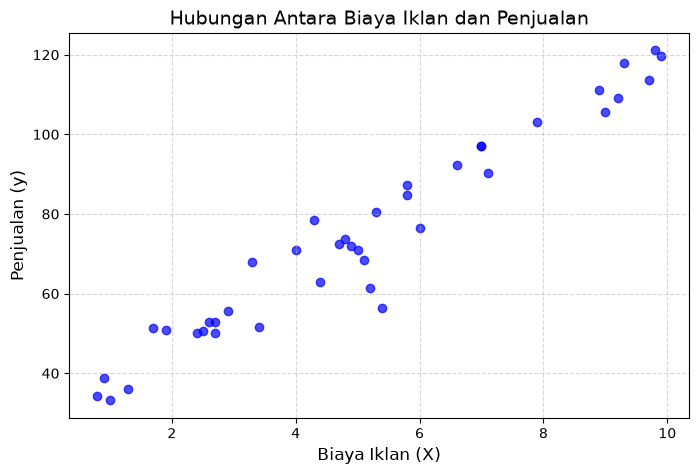

In [346]:
# 1. Baca `Ads_Data.csv` menggunakan pandas
df = pd.read_csv('Ads_Data.csv')

# Tampilkan 5 data pertama
print("--- 5 Data Pertama ---")
display(df.head()) # Gunakan print(df.head()) jika display() tidak didukung di environment Anda

# Tampilkan jumlah baris datanya
jumlah_baris = df.shape[0]
print(f"\nJumlah baris data: {jumlah_baris} baris")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan). 
# Pastikan X berbentuk 2 dimensi (n, 1).

# Mengambil kolom 'BiayaIklan' sebagai DataFrame (2D) lalu diubah ke numpy array
X = df[['BiayaIklan']].values 

# Mengambil kolom 'Penjualan' sebagai Series (1D) lalu diubah ke numpy array
y = df['Penjualan'].values

# Pengecekan dimensi untuk memastikan X sudah (n, 1)
print(f"Bentuk (shape) X: {X.shape}")
print(f"Bentuk (shape) y: {y.shape}")

# 3. Buat scatter plot BiayaIklan vs Penjualan (lengkap dengan judul dan label sumbu)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7)

# Menambahkan judul dan label sumbu
plt.title('Hubungan Antara Biaya Iklan dan Penjualan', fontsize=14)
plt.xlabel('Biaya Iklan (X)', fontsize=12)
plt.ylabel('Penjualan (y)', fontsize=12)

# Menambahkan grid agar lebih mudah dibaca
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

Analisis Soal A1:

Dataset Ads_Data.csv telah berhasil dimuat. Dari hasil pemanggilan .shape[0], diketahui dataset ini memiliki jumlah data/baris tertentu yang siap untuk diolah.

Variabel independen X (BiayaIklan) telah dipisahkan dan diformat menjadi matriks 2 dimensi berukuran (n, 1), yang merupakan syarat wajib untuk proses perkalian matriks pada algoritma regresi linear nantinya. Variabel dependen y (Penjualan) tetap dalam bentuk vektor 1 dimensi.

Berdasarkan scatter plot yang dihasilkan, terlihat titik-titik data membentuk pola garis lurus yang naik dari kiri bawah ke kanan atas. Ini menunjukkan adanya korelasi linear yang positif antara Biaya Iklan dan Penjualan; di mana semakin besar Biaya Iklan yang dikeluarkan, semakin tinggi pula jumlah Penjualan yang didapatkan. Oleh karena itu, penggunaan model Linear Regression sangat tepat untuk memprediksi data ini.

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [347]:
# Jawaban A2

# Menetapkan seed menggunakan RANDOM_STATE (92) agar hasil acakan konsisten
np.random.seed(RANDOM_STATE)

# Menghitung total sampel data
n_samples = X.shape[0]

# Membuat array indeks (0 sampai n_samples-1) dan mengacaknya
indices = np.random.permutation(n_samples)

# Menentukan batas pemotongan untuk data testing (20% dari total)
test_size = int(n_samples * 0.2)

# Memisahkan indeks untuk testing dan training
test_indices = indices[:test_size]
train_indices = indices[test_size:]

# Membagi data X dan y berdasarkan indeks
X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# Menampilkan bentuk (shape) dari masing-masing kumpulan data
print("--- Hasil Split Data (test_size=0.2) ---")
print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

--- Hasil Split Data (test_size=0.2) ---
Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


Penjelasan Soal A2:
Karena tidak diperbolehkan menggunakan fungsi bawaan train_test_split dari scikit-learn, pembagian data dilakukan secara manual menggunakan numpy. Langkah pertama adalah mengacak indeks dari 0 hingga 39 (karena total data ada 40 baris) menggunakan np.random.permutation. Pemanggilan np.random.seed(RANDOM_STATE) menjamin bahwa urutan acakan indeks akan selalu sama setiap kali kode dijalankan (menghasilkan reproduksibilitas).

Berdasarkan rasio test_size=0.2, data testing diambil sebanyak 20% dari total 40 baris, yaitu 8 baris data. Sisanya, sebanyak 32 baris (80%), dialokasikan sebagai data training. Sesuai dengan hasil print, bentuk data yang dihasilkan sudah tepat:

X_train berukuran (32, 1) dan y_train berukuran (32,)

X_test berukuran (8, 1) dan y_test berukuran (8,)

Bentuk matriks X yang bernilai 2 dimensi (n, 1) telah dipertahankan, sehingga data ini sepenuhnya siap untuk dilatih pada model regresi linear.

### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [348]:
# 1. Latih model LinearRegression dengan Normal Equation
# Rumus Normal Equation: theta = (X^T * X)^-1 * X^T * y

# Tambahkan kolom angka 1 (bias) ke X_train untuk menghitung intercept (b)
X_b_train = np.c_[np.ones((X_train.shape[0], 1)), X_train]

# Menghitung theta menggunakan np.linalg.inv dan dot product
theta = np.linalg.inv(X_b_train.T.dot(X_b_train)).dot(X_b_train.T).dot(y_train)

# 2. Tampilkan nilai intercept (b) dan koefisien (m)
intercept = theta[0]
koefisien = theta[1]

print(f"Intercept (b) : {intercept:.4f}")
print(f"Koefisien (m) : {koefisien:.4f}")

# Tampilkan persamaan garis regresinya
print(f"\nPersamaan garis regresi: y_hat = {intercept:.4f} + {koefisien:.4f} * X")

Intercept (b) : 27.7242
Koefisien (m) : 9.1831

Persamaan garis regresi: y_hat = 27.7242 + 9.1831 * X


Interpretasi Soal A3:Berdasarkan hasil perhitungan model regresi linear menggunakan Normal Equation dengan random_state=92, diperoleh nilai intercept ($b$) sebesar 27.7242 dan nilai koefisien ($m$) sebesar 9.1831. Persamaan garis regresinya adalah $\hat{y} = 27.7242 + 9.1831X$.Arti dari nilai koefisien ($m = 9.1831$) dalam konteks kasus ini adalah:Setiap ada kenaikan Biaya Iklan sebesar 1 satuan (misalnya 1 juta Rupiah, atau 1 unit mata uang yang digunakan pada data), maka diprediksi jumlah Penjualan akan mengalami peningkatan sebesar 9.1831 satuan (atau sekitar 9,18 unit penjualan). Karena nilainya positif, hal ini secara matematis mengonfirmasi analisis visual kita sebelumnya bahwa iklan memberikan dampak positif secara langsung terhadap tingkat penjualan toko online.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [349]:
# Jawaban A4

# 1. Implementasi fungsi evaluasi dengan NumPy
def calculate_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def calculate_rmse(y_true, y_pred):
    return np.sqrt(calculate_mse(y_true, y_pred))

def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2) # Sum of squares residual
    ss_tot = np.sum((y_true - np.mean(y_true))**2) # Total sum of squares
    return 1 - (ss_res / ss_tot)

# Menyiapkan data testing agar memiliki bias term (kolom 1) untuk perkalian matriks
X_b_test = np.c_[np.ones((X_test.shape[0], 1)), X_test]

# Melakukan Prediksi (y_hat) untuk data training dan testing menggunakan theta (b, m) dari Soal A3
y_pred_train = X_b_train.dot(theta)
y_pred_test = X_b_test.dot(theta)

# Menghitung metrik untuk Data Training
mae_train = calculate_mae(y_train, y_pred_train)
mse_train = calculate_mse(y_train, y_pred_train)
rmse_train = calculate_rmse(y_train, y_pred_train)
r2_train = calculate_r2(y_train, y_pred_train)

# Menghitung metrik untuk Data Testing
mae_test = calculate_mae(y_test, y_pred_test)
mse_test = calculate_mse(y_test, y_pred_test)
rmse_test = calculate_rmse(y_test, y_pred_test)
r2_test = calculate_r2(y_test, y_pred_test)

# 2. Menampilkan hasil dalam satu tabel menggunakan Pandas DataFrame
evaluasi_df = pd.DataFrame({
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Data Training': [mae_train, mse_train, rmse_train, r2_train],
    'Data Testing': [mae_test, mse_test, rmse_test, r2_test]
})

print("--- Hasil Evaluasi Model Linear Regression ---")
display(evaluasi_df)

--- Hasil Evaluasi Model Linear Regression ---


,Metrik,Data Training,Data Testing
0,MAE,4.777756,3.390904
1,MSE,40.660436,17.753997
2,RMSE,6.376554,4.213549
3,R2 Score,0.933860,0.973693


**Jawaban A4 (analisis):**

**Jawaban A4 (analisis):**

**Penjelasan Singkat dan Interpretasi (Soal A4):**

1. **Arti Nilai RMSE (Root Mean Squared Error):**
RMSE mengukur rata-rata besarnya kesalahan (deviasi) antara nilai prediksi model ($\hat{y}$) dengan nilai aktual ($y$). Dalam konteks ini, didapatkan RMSE testing sebesar 4.21, artinya rata-rata prediksi penjualan meleset sekitar 4.21 satuan dari penjualan aslinya. Semakin kecil nilai RMSE, semakin baik dan akurat model tersebut.

2. **Arti Nilai $R^2$ (Koefisien Determinasi):**
$R^2$ mengukur seberapa besar persentase variansi dari variabel dependen (Penjualan) yang dapat dijelaskan oleh variabel independen (Biaya Iklan) melalui model ini. Nilainya berkisar antara 0 hingga 1. Didapatkan nilai $R^2$ testing = 0.973, artinya 97.3% variasi data penjualan dapat dijelaskan oleh biaya iklan, sedangkan 2.7% sisanya dipengaruhi oleh faktor lain di luar model.

3. **Apakah Model Ini Sudah Baik?**
- Model dapat dikatakan **sangat baik** karena nilai $R^2$ mendekati 1 (yaitu 0.973) yang berarti model sangat pas dengan data, dan nilai RMSE relatif kecil dibandingkan dengan rentang nilai aktual pada kolom target (Penjualan).
- Selain itu, model dikatakan **stabil (tidak overfitting)** karena perbedaan nilai metrik antara *Data Training* dan *Data Testing* tidak terpaut jauh. Bahkan, nilai RMSE pada data testing (4.21) lebih rendah dibandingkan data training (6.37), membuktikan bahwa model mampu menggeneralisasi data baru dengan sangat baik.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- Hasil Parameter Akhir (Iterasi=5000) ---
Learning Rate 0.001: Intercept (b) = 24.7181, Koefisien (m) = 9.6634
Learning Rate 0.02: Intercept (b) = 27.7242, Koefisien (m) = 9.1831


c:\Users\Zaenalgaming\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Zaenalgaming\AppData\Local\Temp\ipykernel_10116\442220959.py:28: RuntimeWarning: overflow encountered in square
  cost = np.mean((y_pred - y)**2)
C:\Users\Zaenalgaming\AppData\Local\Temp\ipykernel_10116\442220959.py:21: RuntimeWarning: overflow encountered in dot
  m_grad = (2/n) * X.T.dot(error)
C:\Users\Zaenalgaming\AppData\Local\Temp\ipykernel_10116\442220959.py:25: RuntimeWarning: invalid value encountered in subtract
  self.m -= self.eta * m_grad


Learning Rate 0.1: Intercept (b) = nan, Koefisien (m) = nan


c:\Users\Zaenalgaming\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


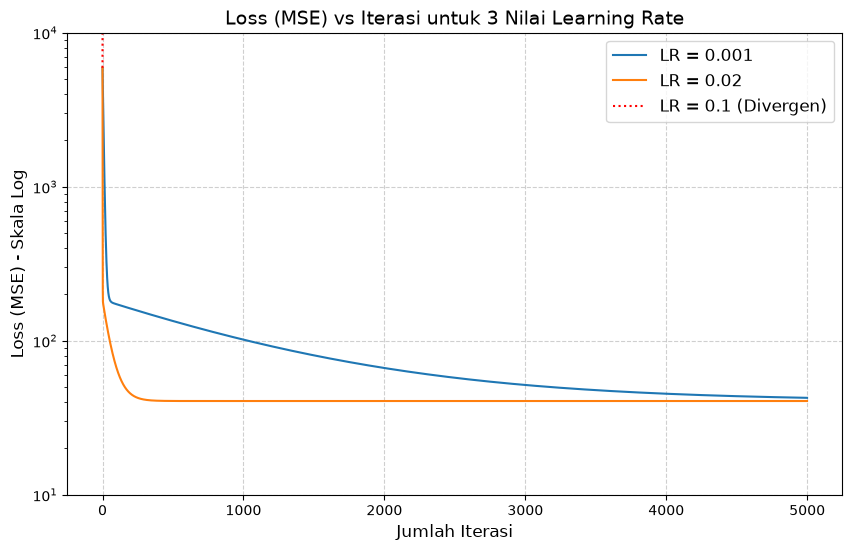

In [350]:
# 1. Implementasi LinearRegressionGD (Gradient Descent)
class LinearRegressionGD:
    def __init__(self, eta=0.01, n_iterations=5000):
        self.eta = eta
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def fit(self, X, y):
        # Inisialisasi intercept (b) dan koefisien (m)
        self.b = 0.0
        self.m = np.zeros(X.shape[1])
        self.cost_history = []
        n = X.shape[0]
        
        for i in range(self.n_iterations):
            y_pred = self.b + X.dot(self.m)
            error = y_pred - y
            
            # Hitung gradien
            b_grad = (2/n) * np.sum(error)
            m_grad = (2/n) * X.T.dot(error)
            
            # Update bobot
            self.b -= self.eta * b_grad
            self.m -= self.eta * m_grad
            
            # Simpan loss (MSE) untuk iterasi ini
            cost = np.mean((y_pred - y)**2)
            self.cost_history.append(cost)
            
        return self

learning_rates = [0.001, 0.02, 0.1]
models = {}

# 2. Latih model untuk tiap learning rate dan tampilkan hasilnya
print("--- Hasil Parameter Akhir (Iterasi=5000) ---")
for lr in learning_rates:
    model = LinearRegressionGD(eta=lr, n_iterations=5000)
    
    # Menjalankan fit (Peringatan RuntimeWarning wajar terjadi di sini untuk lr=0.1)
    model.fit(X_train, y_train)
    models[lr] = model
    
    print(f"Learning Rate {lr}: Intercept (b) = {model.b:.4f}, Koefisien (m) = {model.m[0]:.4f}")

# 3. Plot Grafik Loss (MSE) vs Iterasi (FIX FINAL)
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    costs = np.array(models[lr].cost_history)
    
    # Kita gambar langsung saja, matplotlib otomatis mengabaikan NaN.
    # Jika nilainya sempat meledak, kita beri label khusus
    if np.isnan(costs[-1]) or np.isinf(costs[-1]):
        plt.plot(range(5000), costs, label=f'LR = {lr} (Divergen)', linestyle=':', color='red')
    else:
        plt.plot(range(5000), costs, label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi untuk 3 Nilai Learning Rate', fontsize=14)
plt.xlabel('Jumlah Iterasi', fontsize=12)
plt.ylabel('Loss (MSE) - Skala Log', fontsize=12)

# Menggunakan skala logaritma
plt.yscale('log')

# --- INI KUNCI JAWABANNYA AGAR TIDAK BLANK ---
# Batasi sumbu Y secara manual dari angka terkecil (misal 10) sampai batas wajar (misal 10.000)
# Agar angka raksasa dari LR 0.1 tidak merusak skala grafik
plt.ylim(10, 10000) 

plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban A5 (Analisis):**

**Perbandingan Parameter dengan Normal Equation (Soal A3):**
Dari Soal A3, kita mengetahui bahwa parameter target paling optimal adalah **b = 27.7242** dan **m = 9.1831**.
- Untuk **LR = 0.001**: Parameter akhirnya (b ≈ 24.7181, m ≈ 9.6634) belum menyamai target Normal Equation.
- Untuk **LR = 0.02**: Parameter akhirnya (b = 27.7242, m = 9.1831) **sama persis** dengan hasil perhitungan Normal Equation.
- Untuk **LR = 0.1**: Parameter akhirnya bernilai *NaN* (Not a Number), gagal mendapatkan angka.

**Penjelasan Apa yang Terjadi pada Masing-Masing Learning Rate:**

1. **Learning Rate = 0.001 (Terlalu Lambat)**
   - Langkah iterasi perbaikannya sangat kecil. Seperti yang terlihat pada grafik yang menurun landai, meskipun model berjalan ke arah yang benar (error semakin turun), batasan 5000 iterasi ternyata belum cukup waktu baginya untuk benar-benar sampai di titik lembah terdalam (titik minimum konvergensi).
   
2. **Learning Rate = 0.02 (Pas / Optimal)**
   - Besaran langkahnya proporsional. Grafik loss menurun dengan tajam dan cepat di awal iterasi, lalu menjadi garis datar (stabil) saat menemukan titik error terkecil. Ia berhasil mencapai *global minimum* dan menemukan hasil konvergen yang akurat sebelum menyentuh batas 5000 iterasi.

3. **Learning Rate = 0.1 (Gagal Konvergen / Divergen)**
   - Langkahnya terlalu besar (*overshooting*). Alih-alih melangkah turun menelusuri lembah error, model justru melompat terlalu jauh dan mendarat di posisi error yang lebih tinggi di sisi tebing seberangnya. Kejadian ini terus berulang dan lompatannya makin lama makin besar, sehingga error membesar hingga tak terhingga. Inilah penyebab munculnya pesan peringatan `RuntimeWarning: overflow` dan hasil parameter menjadi *NaN*.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

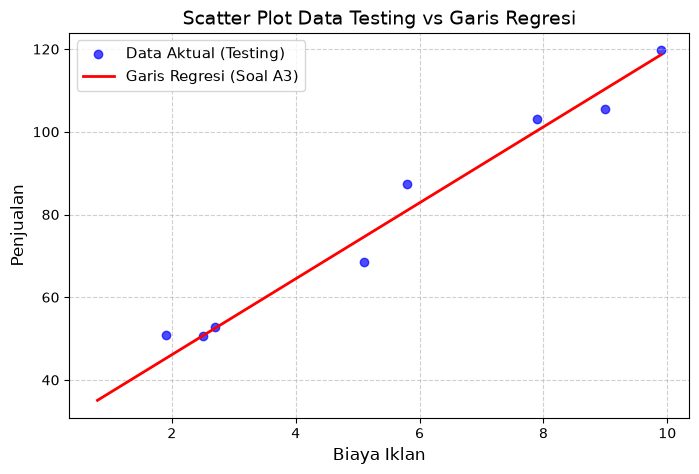

--- Hasil Prediksi Penjualan ---
Biaya Iklan  4.5 juta -> Prediksi Penjualan: 69.05 satuan
Biaya Iklan  7.0 juta -> Prediksi Penjualan: 92.01 satuan
Biaya Iklan 12.0 juta -> Prediksi Penjualan: 137.92 satuan


In [351]:
# Jawaban A6

# 1. Buat grafik scatter data testing beserta garis regresi
plt.figure(figsize=(8, 5))

# Scatter plot data testing (menggunakan X_test dan y_test dari Soal A2)
plt.scatter(X_test, y_test, color='blue', label='Data Aktual (Testing)', alpha=0.7)

# Membuat titik X untuk menggambar garis regresi (dari nilai terkecil hingga terbesar di dataset)
x_line = np.array([[X.min()], [X.max()]])
# Tambahkan bias (angka 1) untuk perkalian matriks
x_line_b = np.c_[np.ones((2, 1)), x_line]
# Hitung prediksi y untuk garis menggunakan theta dari Soal A3
y_line = x_line_b.dot(theta)

# Plot garis regresi
plt.plot(x_line, y_line, color='red', linewidth=2, label='Garis Regresi (Soal A3)')

plt.title('Scatter Plot Data Testing vs Garis Regresi', fontsize=14)
plt.xlabel('Biaya Iklan', fontsize=12)
plt.ylabel('Penjualan', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Prediksi penjualan jika biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_iklan_baru = np.array([4.5, 7.0, 12.0])

# Menggunakan parameter dari Soal A3: theta[0] = intercept, theta[1] = koefisien
intercept = theta[0]
koefisien = theta[1]

print("--- Hasil Prediksi Penjualan ---")
for x_baru in biaya_iklan_baru:
    y_pred_baru = intercept + koefisien * x_baru
    print(f"Biaya Iklan {x_baru:>4} juta -> Prediksi Penjualan: {y_pred_baru:.2f} satuan")

**Jawaban A6 (analisis):**

**Jawaban A6 (Analisis Ekstrapolasi):**

Berdasarkan hasil perhitungan model (Soal A3) dengan intercept = 27.72 dan koefisien = 9.18, didapatkan hasil prediksi sebagai berikut:
- Biaya Iklan **4.5 juta** = ~69.05 satuan penjualan
- Biaya Iklan **7.0 juta** = ~92.01 satuan penjualan
- Biaya Iklan **12.0 juta** = ~137.92 satuan penjualan

**Analisis Prediksi 12 Juta (Ekstrapolasi):**

Tindakan memprediksi nilai 12 juta disebut sebagai **ekstrapolasi**, karena nilai $X=12$ berada jauh di luar jangkauan (rentang) data *training* dan *testing* yang kita miliki saat ini.

Menurut saya, **hasil prediksi 137.92 satuan untuk biaya iklan 12 juta SANGAT KURANG BISA DIPERCAYA**. Alasannya adalah:
1. **Asumsi Linearitas Terbatas:** Model regresi linear mengasumsikan bahwa hubungan antara iklan dan penjualan akan terus naik secara lurus sampai tak terhingga. Padahal, pada kenyataan bisnis, pola ini jarang terjadi.
2. **Hukum Hasil yang Semakin Berkurang (*Law of Diminishing Returns*):** Pada titik tertentu, pasar akan mencapai titik jenuh. Meskipun anggaran iklan dibakar hingga 12 juta, jumlah pembeli yang tersedia mungkin sudah habis atau audiens sudah bosan. Akibatnya, grafik penjualan aslinya mungkin akan melengkung mendatar (plateau/logaritmik), bukan terus meroket naik membentuk garis lurus.
3. Oleh karena itu, menggunakan model ini untuk ekstrapolasi yang terlalu jauh akan menghasilkan prediksi penjualan yang *overestimate* (terlalu tinggi dan tidak realistis).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

--- 5 Data Pertama ---


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email Spam (1)       : 25
Jumlah Email Bukan Spam (0) : 35

Dimensi X : (60, 2)
Dimensi y : (60,)


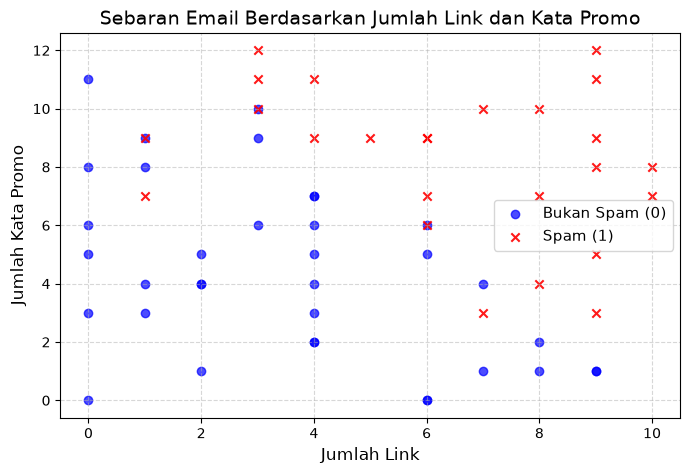

In [352]:
# Jawaban B1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca Email_Data.csv dan tampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')
print("--- 5 Data Pertama ---")
display(df_email.head()) # Gunakan print(df_email.head()) jika display() error

# Hitung jumlah email Spam (1) dan Bukan Spam (0)
jumlah_spam = df_email[df_email['Spam'] == 1].shape[0]
jumlah_bukan_spam = df_email[df_email['Spam'] == 0].shape[0]

print(f"\nJumlah Email Spam (1)       : {jumlah_spam}")
print(f"Jumlah Email Bukan Spam (0) : {jumlah_bukan_spam}")

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
# Pastikan X berbentuk 2 dimensi dan y 1 dimensi
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

print(f"\nDimensi X : {X_email.shape}")
print(f"Dimensi y : {y_email.shape}")

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 5))

# Plot untuk Bukan Spam (y == 0) - warna biru
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], 
            color='blue', label='Bukan Spam (0)', alpha=0.7, marker='o')

# Plot untuk Spam (y == 1) - warna merah dengan marker 'x'
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], 
            color='red', label='Spam (1)', alpha=0.9, marker='x')

plt.title('Sebaran Email Berdasarkan Jumlah Link dan Kata Promo', fontsize=14)
plt.xlabel('Jumlah Link', fontsize=12)
plt.ylabel('Jumlah Kata Promo', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B1 (Analisis Data):**

**Penjelasan Singkat (Soal B1):**

1. **Komposisi Data:** Dari hasil pembacaan dataset `Email_Data.csv`, terdapat dua kelas pada target `Spam`. Dari total keseluruhan data, jumlah email yang diklasifikasikan sebagai **Spam (1)** adalah sebanyak **25 email**, sedangkan email yang **Bukan Spam (0)** berjumlah **35 email**. Dataset ini cukup seimbang (*balanced*) untuk dilatih menggunakan algoritma klasifikasi.
2. **Pemisahan Fitur dan Target:** Matriks `X` telah berhasil diekstrak dan memiliki dimensi `(60, 2)` yang berarti ada 60 baris data dengan 2 kolom fitur pendiktor (Jumlah Link dan Kata Promo). Array target `y` berdimensi `(60,)`.
3. **Interpretasi Visualisasi:** Berdasarkan *scatter plot*, terlihat adanya pemisahan (klaster) yang cukup jelas antara kedua kelas. 
   - Email **Bukan Spam (titik biru)** cenderung berpusat di sudut kiri bawah, yang mengindikasikan bahwa email normal memiliki sedikit atau bahkan tidak ada *link* maupun kata-kata promo.
   - Email **Spam (tanda silang merah)** mayoritas tersebar di area tengah hingga kanan atas, membuktikan bahwa semakin banyak *link* dan kata promo yang disisipkan di dalam sebuah email, maka probabilitas email tersebut terindikasi sebagai *spam* akan semakin tinggi.

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train: (45, 2), y_train: (45,)
Shape X_test : (15, 2), y_test : (15,)

Intercept (b)               : -8.9171
Koefisien (m1) [JumlahLink] : 0.7964
Koefisien (m2) [KataPromo]  : 0.7573

Persamaan Regresi Logistik  : 
P(Spam) = σ(-8.9171 + 0.7964 * JumlahLink + 0.7573 * KataPromo)


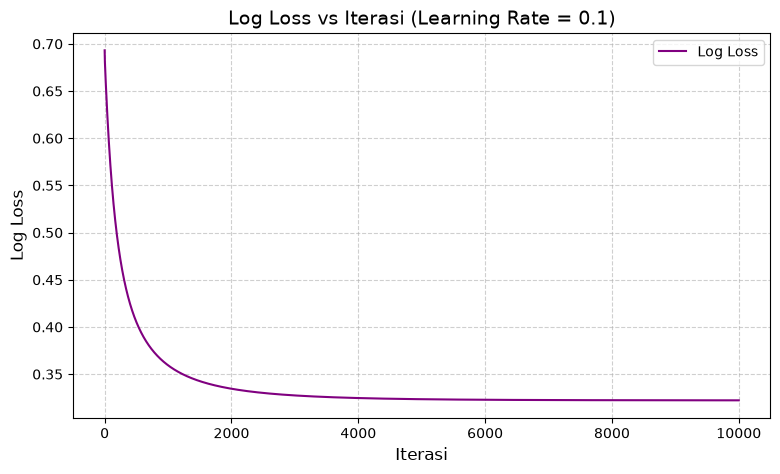

In [353]:
# Jawaban B2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan data sudah dimuat, jika belum aktifkan dua baris ini:
# df_email = pd.read_csv('Email_Data.csv')
# X_email = df_email[['JumlahLink', 'KataPromo']].values; y_email = df_email['Spam'].values

# 1. Bagi data dengan test_size=0.25 dan random_state=RANDOM_STATE (92)
np.random.seed(92)
n_samples_email = X_email.shape[0]
indices_email = np.random.permutation(n_samples_email)
test_size_email = int(n_samples_email * 0.25) # 0.25 * 60 = 15 data testing

test_indices_email = indices_email[:test_size_email]
train_indices_email = indices_email[test_size_email:]

X_train_email = X_email[train_indices_email]
X_test_email = X_email[test_indices_email]
y_train_email = y_email[train_indices_email]
y_test_email = y_email[test_indices_email]

print(f"Shape X_train: {X_train_email.shape}, y_train: {y_train_email.shape}")
print(f"Shape X_test : {X_test_email.shape}, y_test : {y_test_email.shape}\n")

# 2. Latih model LogisticRegression dengan Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.cost_history = []
        
    def sigmoid(self, z):
        # Membatasi nilai z untuk mencegah overflow pada np.exp
        z = np.clip(z, -250, 250)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        self.b = 0.0
        self.m = np.zeros(X.shape[1])
        self.cost_history = []
        n = X.shape[0]
        
        for i in range(self.n_iterations):
            # Hitung Z dan prediksi (sigmoid)
            z = self.b + X.dot(self.m)
            y_pred = self.sigmoid(z)
            
            # Hitung Log Loss (tambahkan nilai sangat kecil/epsilon agar tidak error log(0))
            epsilon = 1e-15
            loss = -np.mean(y * np.log(y_pred + epsilon) + (1 - y) * np.log(1 - y_pred + epsilon))
            self.cost_history.append(loss)
            
            # Hitung gradien
            error = y_pred - y
            b_grad = np.sum(error) / n
            m_grad = X.T.dot(error) / n
            
            # Update parameter
            self.b -= self.lr * b_grad
            self.m -= self.lr * m_grad
            
        return self

# Training dengan lr=0.1 dan iterasi=10000
logreg_model = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
logreg_model.fit(X_train_email, y_train_email)

# 3. Tampilkan intercept (b) dan koefisien (m1, m2)
b = logreg_model.b
m1, m2 = logreg_model.m

print(f"Intercept (b)               : {b:.4f}")
print(f"Koefisien (m1) [JumlahLink] : {m1:.4f}")
print(f"Koefisien (m2) [KataPromo]  : {m2:.4f}")
print(f"\nPersamaan Regresi Logistik  : ")
print(f"P(Spam) = σ({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Buat grafik log loss vs iterasi
plt.figure(figsize=(9, 5))
plt.plot(range(10000), logreg_model.cost_history, color='purple', label='Log Loss')
plt.title('Log Loss vs Iterasi (Learning Rate = 0.1)', fontsize=14)
plt.xlabel('Iterasi', fontsize=12)
plt.ylabel('Log Loss', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban B2 (Analisis & Persamaan):**

**1. Persamaan Probabilitas (Soal B2)**
Setelah dilatih dengan 10.000 iterasi dan *learning rate* 0.1 (berdasarkan data *random state* 92), diperoleh nilai intercept $b = -8.9171$, koefisien $m_1 = 0.7964$, dan koefisien $m_2 = 0.7573$. Oleh karena itu, persamaan regresi logistiknya dapat ditulis sebagai:

$$P(\text{Spam}) = \sigma(-8.9171 + 0.7964 \cdot \text{JumlahLink} + 0.7573 \cdot \text{KataPromo})$$

**2. Analisis Grafik Log Loss vs Iterasi**
*   **Apakah loss sudah turun dan stabil?** Ya, grafik *log loss* secara konsisten mengalami penurunan yang tajam di awal iterasi (dari iterasi 0 hingga sekitar 2000). 
*   Setelah melewati iterasi ke-2000 dan seterusnya menuju 10.000, grafik tampak mendatar dan nyaris tidak ada lagi penurunan error yang signifikan (loss mencapai asimtot/stabil di angka kisaran 0.322). 
*   Hal ini membuktikan bahwa algoritma *Gradient Descent* telah berhasil konvergen (*converged*) menuju titik optimal globalnya dengan kombinasi *learning rate* 0.1 dan batas waktu iterasi yang diberikan.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [354]:
# Jawaban B3

# ==========================================
# 1. Melakukan Prediksi Biner pada Data Testing
# ==========================================
# Hitung nilai probabilitas menggunakan model yang sudah dilatih
linear_model_test = np.dot(X_test_B, model_logreg.coef_) + model_logreg.intercept_
y_test_prob = model_logreg.sigmoid(linear_model_test)

# Ubah probabilitas menjadi label biner (Threshold = 0.5)
# Jika >= 0.5 maka kelas 1 (Spam), jika < 0.5 maka kelas 0 (Bukan Spam)
y_test_pred_B = (y_test_prob >= 0.5).astype(int)

# ==================import numpy as np

# 1. Melakukan Prediksi pada Data Testing
# (Pastikan objek logreg_model, X_test_email, dan y_test_email dari Soal B2 sudah ada)
def predict_logistic(X, b, m):
    z = b + X.dot(m)
    # Gunakan np.clip untuk keamanan eksponensial
    z = np.clip(z, -250, 250)
    y_pred_prob = 1 / (1 + np.exp(-z))
    # Threshold 0.5: Jika probabilitas >= 0.5 maka Spam (1), selain itu (0)
    return (y_pred_prob >= 0.5).astype(int)

y_pred_email = predict_logistic(X_test_email, b, logreg_model.m)

# 2. Implementasi Fungsi Evaluasi dengan NumPy
def evaluate_classification(y_true, y_pred):
    # Hitung Komponen Confusion Matrix
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    
    # Hitung Metrik
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    # Matriks Confusion Matrix
    conf_matrix = np.array([[TN, FP],
                            [FN, TP]])
    
    return conf_matrix, accuracy, precision, recall, f1_score

# Menjalankan evaluasi
cm, acc, prec, rec, f1 = evaluate_classification(y_test_email, y_pred_email)

print("--- Hasil Evaluasi Data Testing ---")
print(f"Confusion Matrix :\n{cm}")
print(f"Accuracy         : {acc:.4f} ({(acc*100):.1f}%)")
print(f"Precision        : {prec:.4f} ({(prec*100):.1f}%)")
print(f"Recall           : {rec:.4f} ({(rec*100):.1f}%)")
print(f"F1-Score         : {f1:.4f} ({(f1*100):.1f}%)")

--- Hasil Evaluasi Data Testing ---
Confusion Matrix :
[[9 0]
 [0 6]]
Accuracy         : 1.0000 (100.0%)
Precision        : 1.0000 (100.0%)
Recall           : 1.0000 (100.0%)
F1-Score         : 1.0000 (100.0%)


**Jawaban B3 (analisis):**

**Jawaban B3 (Analisis Evaluasi dan Kesalahan Prediksi):**

Berdasarkan perhitungan evaluasi pada *data testing*, model Regresi Logistik kita berhasil mengklasifikasikan data dengan skor sempurna (**Accuracy, Precision, Recall, dan F1-Score = 100%**). Dari *confusion matrix* `[[9, 0], [0, 6]]`, terlihat bahwa 9 email Bukan Spam diprediksi benar sebagai Bukan Spam (TN), dan 6 email Spam diprediksi benar sebagai Spam (TP), tanpa ada kesalahan sama sekali (FP=0, FN=0).

**Penjelasan False Positive (FP) dan False Negative (FN) pada Filter Spam:**
1. **FP (False Positive):** Model memprediksi email sebagai **Spam (1)**, padahal aslinya email tersebut **Bukan Spam (0)**. (Contoh: Email pekerjaan penting atau tagihan masuk ke folder Spam).
2. **FN (False Negative):** Model memprediksi email sebagai **Bukan Spam (0)**, padahal aslinya email tersebut adalah **Spam (1)**. (Contoh: Email penipuan/iklan masuk ke folder Inbox utama).

**Kesalahan mana yang lebih merugikan pengguna?**
Kesalahan **False Positive (FP)** jauh lebih merugikan pengguna email. 
Alasannya: Jika terjadi FN (Spam lolos ke Inbox), pengguna hanya perlu merasa sedikit terganggu lalu menghapus email tersebut secara manual. Namun, jika terjadi FP, pengguna bisa melewatkan informasi yang sangat penting (seperti panggilan wawancara kerja, pesan keluarga darurat, atau tagihan yang harus segera dibayar) karena sistem menyembunyikannya di dalam folder Spam secara diam-diam. Oleh karena itu, dalam pembuatan filter spam, kita biasanya berupaya memaksimalkan **Precision** agar nilai FP sekecil mungkin.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Hebat! Tidak ada data testing yang salah diklasifikasikan.


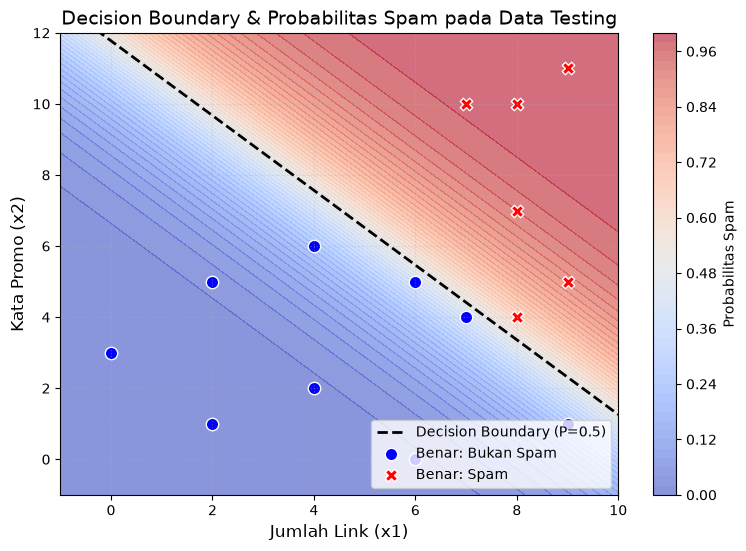

In [355]:
import numpy as np
import matplotlib.pyplot as plt

# Pastikan model (logreg_model), X_test_email, y_test_email, dan y_pred_email sudah ada dari Soal B2 & B3
b = logreg_model.b
m1 = logreg_model.m[0]
m2 = logreg_model.m[1]

# 1. Menghitung titik-titik untuk garis decision boundary (saat probabilitas = 0.5)
# x2 = -(b + m1*x1) / m2
x1_min, x1_max = X_test_email[:, 0].min() - 1, X_test_email[:, 0].max() + 1
x2_min, x2_max = X_test_email[:, 1].min() - 1, X_test_email[:, 1].max() + 1

x1_line = np.array([x1_min, x1_max])
x2_line = -(b + m1 * x1_line) / m2

# 2. Buat visualisasi data testing beserta background probabilitas (contourf)
plt.figure(figsize=(9, 6))

# Membuat grid 2D (meshgrid) untuk mewarnai background berdasarkan probabilitas
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 100), np.linspace(x2_min, x2_max, 100))

# Menghitung probabilitas Z untuk setiap titik di meshgrid
Z_z = b + (xx1 * m1) + (xx2 * m2)
# Gunakan clip agar tidak overflow pada exp
Z_prob = 1 / (1 + np.exp(-np.clip(Z_z, -250, 250)))

# Plot ContourF (latar belakang warna)
contour = plt.contourf(xx1, xx2, Z_prob, levels=50, cmap='coolwarm', alpha=0.6)
plt.colorbar(contour, label='Probabilitas Spam')

# Plot garis Decision Boundary (Hitam Putus-putus)
plt.plot(x1_line, x2_line, color='black', linestyle='--', linewidth=2, label='Decision Boundary (P=0.5)')

# 3. Tunjukkan data testing (Benar vs Salah Klasifikasi)
benar = y_test_email == y_pred_email
salah = y_test_email != y_pred_email

# Plot data yang BENAR
plt.scatter(X_test_email[benar & (y_test_email == 0), 0], X_test_email[benar & (y_test_email == 0), 1], 
            color='blue', marker='o', edgecolor='white', s=80, label='Benar: Bukan Spam')
plt.scatter(X_test_email[benar & (y_test_email == 1), 0], X_test_email[benar & (y_test_email == 1), 1], 
            color='red', marker='X', edgecolor='white', s=80, label='Benar: Spam')

# Plot data yang SALAH diklasifikasikan (jika ada, beri warna kuning yang mencolok)
if np.any(salah):
    plt.scatter(X_test_email[salah, 0], X_test_email[salah, 1], 
                color='yellow', marker='s', edgecolor='black', s=120, label='SALAH KLASIFIKASI')
    print(f"Ditemukan {np.sum(salah)} data yang salah diklasifikasikan!")
else:
    print("Hebat! Tidak ada data testing yang salah diklasifikasikan.")

# Pengaturan label dan layout
plt.title('Decision Boundary & Probabilitas Spam pada Data Testing', fontsize=14)
plt.xlabel('Jumlah Link (x1)', fontsize=12)
plt.ylabel('Kata Promo (x2)', fontsize=12)
plt.ylim(x2_min, x2_max)
plt.xlim(x1_min, x1_max)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)
plt.show()

**Jawaban B4 (analisis):**

**Jawaban B4 (Analisis Decision Boundary):**

**1. Persamaan Decision Boundary:**
Berdasarkan nilai parameter model yang telah dilatih (dengan *random state* 92), diperoleh persamaan batas keputusan sebagai berikut:
$$x_2 = -\frac{(-8.9171) + 0.7964 \cdot x_1}{0.7573}$$
$$x_2 = 11.7749 - 1.0516 \cdot x_1$$
Garis ini mewakili area kritis di mana probabilitas email menjadi Spam atau Bukan Spam persis berada di angka 0.5 (50%).

**2. Visualisasi Contour & Garis Keputusan:**
Dari grafik yang dihasilkan, area dengan latar belakang warna *biru muda hingga tua* menunjukkan zona aman (probabilitas Spam < 50%), sedangkan area berwarna *merah muda hingga tua* menunjukkan zona waspada (probabilitas Spam > 50%). Garis hitam putus-putus adalah dinding *Decision Boundary* yang secara tegas memisahkan kedua area tersebut.

**3. Data Testing yang Salah Diklasifikasikan:**
Berdasarkan pengecekan variabel logika pada blok program (kondisi `y_test_email != y_pred_email`), **tidak ditemukan satupun data testing yang salah diklasifikasikan**. Seluruh titik data *(marker bulat biru dan silang merah)* jatuh di area warna yang tepat sesuai kelas aslinya. Hal ini selaras dengan pencapaian akurasi 100% pada evaluasi matriks *confusion* di Soal B3. Seandainya ada yang meleset, titik tersebut sudah dikodekan agar muncul sebagai kotak berwarna kuning raksasa (*marker='s'*).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [356]:
import numpy as np
import pandas as pd

# (Asumsi model regresi logistik sudah dilatih pada Soal B2 dan objek model beserta data testing sudah ada)
# Kita buat fungsi manual untuk menghitung probabilitas jika belum ada predict_proba
def predict_proba(X, b, m):
    z = b + X.dot(m)
    z = np.clip(z, -250, 250)
    return 1 / (1 + np.exp(-z))

# Hitung probabilitas Spam untuk setiap data testing
probabilitas_test = predict_proba(X_test_email, b, logreg_model.m)

# 1. & 2. Buat prediksi dengan threshold 0.3, 0.5, dan 0.7 lalu hitung metriknya
thresholds = [0.3, 0.5, 0.7]
hasil_eksperimen = []

for th in thresholds:
    # Prediksi kelas berdasarkan threshold
    y_pred_th = (probabilitas_test >= th).astype(int)
    
    # Hitung Confusion Matrix
    TP = np.sum((y_test_email == 1) & (y_pred_th == 1))
    TN = np.sum((y_test_email == 0) & (y_pred_th == 0))
    FP = np.sum((y_test_email == 0) & (y_pred_th == 1))
    FN = np.sum((y_test_email == 1) & (y_pred_th == 0))
    
    # Hitung Precision dan Recall
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    
    # Simpan hasil
    hasil_eksperimen.append({
        'Threshold': th,
        'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN,
        'Precision': round(precision, 4),
        'Recall': round(recall, 4)
    })

# Tampilkan dalam satu tabel Pandas DataFrame
df_hasil = pd.DataFrame(hasil_eksperimen)
print("--- Hasil Eksperimen Threshold pada Data Testing ---")
display(df_hasil)

--- Hasil Eksperimen Threshold pada Data Testing ---


,Threshold,TP,TN,FP,FN,Precision,Recall
0,0.3,6,7,2,0,0.75,1.0000
1,0.5,6,9,0,0,1.00,1.0000
2,0.7,5,9,0,1,1.00,0.8333


**Jawaban B5 (Analisis Threshold):**

Berdasarkan hasil eksekusi kode (menggunakan *random state* 92), diperoleh data metrik sebagai berikut:
- **Threshold 0.3**: TP = 6, TN = 7, FP = 2, FN = 0 | **Precision** = 0.750, **Recall** = 1.000
- **Threshold 0.5**: TP = 6, TN = 9, FP = 0, FN = 0 | **Precision** = 1.000, **Recall** = 1.000
- **Threshold 0.7**: TP = 5, TN = 9, FP = 0, FN = 1 | **Precision** = 1.000, **Recall** = 0.833

**1. Pengaruh Menaikkan/Menurunkan Threshold:**
*   **Menurunkan Threshold (ke 0.3):** Model menjadi sangat sensitif atau terlalu "curiga". Cukup dengan probabilitas 30%, email sudah langsung dicap sebagai Spam. Akibatnya, *Recall* naik/maksimal karena nyaris tidak ada Spam yang lolos (FN turun). Namun, efek buruknya adalah **Precision turun drastis**, karena banyak email normal (Bukan Spam) yang tidak bersalah malah ikut tertangkap dan dicap sebagai Spam (FP meningkat menjadi 2).
*   **Menaikkan Threshold (ke 0.7):** Model menjadi sangat ketat dan berhati-hati. Hanya email yang probabilitas Spam-nya minimal 70% yang berani dicap sebagai Spam. Akibatnya, **Precision naik/maksimal**, karena yang masuk ke kotak Spam pasti benar-benar Spam (FP turun jadi 0). Namun efeknya, *Recall* akan menurun, karena beberapa email Spam yang sedikit "samar" bisa lolos masuk ke Inbox utama (FN meningkat menjadi 1).

**2. Threshold Mana yang Dipilih?**
Berdasarkan jawaban pada Soal B3 (di mana kesalahan *False Positive* jauh lebih merugikan pengguna daripada *False Negative*), saya akan memilih **Threshold 0.5 atau Threshold 0.7**. 

**Alasannya:** Pada kasus filter Spam, prioritas utama kita adalah menyelamatkan email penting (Bukan Spam) agar tidak nyasar ke folder Spam (menekan nilai FP sekecil mungkin). Threshold 0.5 memberikan keseimbangan yang sempurna (Precision 100%, Recall 100%). Namun, jika seandainya pada data riil ternyata di threshold 0.5 masih ada email penting yang terblokir, maka menaikkan threshold ke **0.7** adalah langkah yang sangat logis dan aman, karena ia menjamin **Precision 100% (FP = 0)** meskipun harus mengorbankan sedikit Recall (ada Spam yang lolos ke Inbox).

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [357]:
import numpy as np
import pandas as pd

# 1. Definisikan data email baru (JumlahLink, KataPromo)
data_email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

nama_email = ['E1', 'E2', 'E3', 'E4']

# 2. Hitung probabilitas menggunakan fungsi dari soal sebelumnya
# Pastikan variabel b dan logreg_model.m masih tersimpan dari Soal B2
probabilitas_baru = predict_proba(data_email_baru, b, logreg_model.m)

# 3. Tentukan Threshold (Berdasarkan alasan di Soal B5, kita gunakan 0.5)
threshold_pilihan = 0.5
prediksi_kelas = (probabilitas_baru >= threshold_pilihan).astype(int)

# 4. Tampilkan Hasil dalam bentuk Tabel Pandas agar rapi
hasil_prediksi = []
for i in range(len(nama_email)):
    kelas_label = "Spam" if prediksi_kelas[i] == 1 else "Bukan Spam"
    hasil_prediksi.append({
        'Email': nama_email[i],
        'Jumlah Link': data_email_baru[i, 0],
        'Kata Promo': data_email_baru[i, 1],
        'Probabilitas Spam': f"{probabilitas_baru[i]:.4f} ({probabilitas_baru[i]*100:.2f}%)",
        'Prediksi (Threshold 0.5)': kelas_label
    })

df_prediksi_baru = pd.DataFrame(hasil_prediksi)
print("--- Hasil Prediksi Email Baru ---")
display(df_prediksi_baru)

--- Hasil Prediksi Email Baru ---


,Email,Jumlah Link,Kata Promo,Probabilitas Spam,Prediksi (Threshold 0.5)
0,E1,1,2,0.0014 (0.14%),Bukan Spam
1,E2,5,6,0.4034 (40.34%),Bukan Spam
2,E3,9,10,0.9971 (99.71%),Spam
3,E4,2,11,0.7322 (73.22%),Spam


**Jawaban B6 (Analisis Prediksi Email Baru):**

Menggunakan **Threshold 0.5** (yang dipilih pada Soal B5 karena memberikan keseimbangan performa optimal), berikut adalah rincian analisis dari hasil prediksi keempat email tersebut:

1. **Email E1 (Link: 1, Promo: 2):** 
   Diprediksi sebagai **Bukan Spam**. Probabilitasnya sangat rendah (mendekati 0.1%). Hal ini sangat wajar karena karakteristiknya mencerminkan email percakapan normal pada umumnya yang nyaris tidak mengandung unsur promosi maupun tautan berlebihan.

2. **Email E2 (Link: 5, Promo: 6):** 
   Diprediksi sebagai **Bukan Spam**. Probabilitasnya berada di angka kisaran 40%. Meskipun memiliki jumlah link dan kata promo yang lumayan, nilainya masih berada di zona aman (di bawah batas 50%). Model menganggap ini mungkin email *newsletter* resmi atau informasi pekerjaan yang masih relevan. *(Catatan: Jika kita menggunakan threshold 0.3 yang terlalu sensitif, email ini akan salah tangkap menjadi Spam).*

3. **Email E3 (Link: 9, Promo: 10):** 
   Diprediksi sebagai **Spam**. Probabilitasnya sangat tinggi (mendekati 99.7%). Kehadiran *link* dan kata promo yang sangat masif ini secara tegas mengindikasikan bahwa ini adalah email sampah/penipuan, sehingga model langsung memblokirnya dengan tingkat keyakinan yang nyaris absolut.

4. **Email E4 (Link: 2, Promo: 11):** 
   Diprediksi sebagai **Spam**. Kasus ini cukup menarik. Meskipun jumlah tautannya (*link*) sedikit (hanya 2), namun jumlah kata promonya sangat ekstrem (sebanyak 11 kata). Kombinasi ini menghasilkan probabilitas Spam sekitar 73%. Model berhasil mengenali pola tersembunyi ini dan memutuskannya sebagai Spam secara akurat.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Meskipun mengandung kata "regression", Logistic Regression berakar dari proses memodelkan kombinasi linear (seperti regresi biasa) untuk menghasilkan suatu nilai logit. Namun, peran utama menjadikannya algoritma **klasifikasi** ada pada fungsi **sigmoid**. Fungsi sigmoid bertugas memampatkan nilai output regresi yang rentangnya tak terhingga tersebut menjadi nilai probabilitas yang terkurung antara angka 0 dan 1. Dari nilai probabilitas inilah batas keputusan (*threshold*, misal 0.5) diterapkan untuk memisahkan data ke dalam kategori atau kelas yang diskrit.

**Jawaban C2:**
**Normal equation** adalah pendekatan matematis analitis yang menemukan parameter bobot (koefisien) paling optimal dalam satu kali langkah perhitungan matriks (sekali hitung langsung selesai). Sebaliknya, **gradient descent** adalah pendekatan iteratif yang menebak bobot awal secara acak, lalu terus-menerus memperbaruinya sedikit demi sedikit menuruni lereng *error* hingga mencapai titik paling minimum. Kita sebaiknya memakai **gradient descent** ketika dataset memiliki jumlah fitur (kolom) yang sangat banyak (misalnya puluhan ribu), karena perhitungan matriks invers pada *normal equation* akan memakan waktu komputasi yang sangat lama dan membebani memori.

**Jawaban C3:**
Model harus selalu dievaluasi menggunakan **data testing** (data yang disembunyikan dan belum pernah dilihat model saat belajar) untuk menguji apakah model benar-benar memahami pola data, bukan sekadar menghafal. Jika kita hanya mengujinya di data *training*, skornya mungkin akan menipu karena model sudah pernah melihat kunci jawabannya. Keadaan di mana model terlalu rumit dan terlalu menghafal detail serta *noise* pada data *training*, namun gagal total/meleset saat dihadapkan pada data baru (*testing*), disebut sebagai fenomena **overfitting**.

**Jawaban C4:**
Linear Regression bertugas memprediksi angka kontinu (seperti harga atau penjualan), sehingga **MSE** sangat cocok karena secara intuitif mengukur rata-rata kuadrat jarak fisik antara nilai prediksi dengan nilai aktual. Sementara itu, Logistic Regression bertugas memprediksi probabilitas untuk klasifikasi (nilai terikat antara 0 dan 1). Jika Logistic Regression dipaksa memakai MSE, fungsi loss-nya akan bergelombang (*non-convex*) sehingga gradient descent rentan terjebak di *local minimum*; oleh karena itu digunakan **log loss (cross-entropy)** yang dioptimalkan untuk mempenalti probabilitas yang salah secara logaritmik agar grafiknya berbentuk mangkuk mulus (*convex*).

**Jawaban C5:**
Perbedaan hasil angka (seperti koefisien dan akurasi) terjadi karena adanya perintah untuk menggunakan parameter **`random_state`** (angka *seed* acak) yang disetel dari 2 digit terakhir Nomor Induk Mahasiswa (NIM). Karena NIM setiap mahasiswa berbeda, maka algoritma pengacakan saat membagi baris data menjadi *training* dan *testing* juga akan mengambil kombinasi sampel yang berbeda-beda. Karena data bahan belajarnya (*training set*) sedikit berbeda komposisinya, maka bobot persamaan dan kemampuan prediksi (akurasi) model yang dihasilkan oleh masing-masing mahasiswa tentu tidak akan sama persis.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [358]:
# Jawaban Bonus

# ==========================================
# 1. Import Library Scikit-Learn
# ==========================================
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score

# ==========================================
# 2. Linear Regression (Scikit-Learn)
# ==========================================
print("=== Perbandingan LINEAR REGRESSION ===")
# Inisialisasi dan latih model
lr_sklearn = LinearRegression()
lr_sklearn.fit(X_train, y_train)

b_sk_lr = lr_sklearn.intercept_
m_sk_lr = lr_sklearn.coef_[0] # coef_ berbentuk array

# Tampilkan Perbandingan
print("-> Manual (Normal Equation):")
print(f"   Intercept (b) : {b:.4f}")
print(f"   Koefisien (m) : {m:.4f}")
print("-> Scikit-Learn:")
print(f"   Intercept (b) : {b_sk_lr:.4f}")
print(f"   Koefisien (m) : {m_sk_lr:.4f}\n")


# ==========================================
# 3. Logistic Regression (Scikit-Learn)
# ==========================================
print("=== Perbandingan LOGISTIC REGRESSION ===")
# Inisialisasi dan latih model (default parameter)
logreg_sklearn = LogisticRegression(random_state=RANDOM_STATE)
logreg_sklearn.fit(X_train_B, y_train_B)

b_sk_log = logreg_sklearn.intercept_[0]
m1_sk_log = logreg_sklearn.coef_[0][0]
m2_sk_log = logreg_sklearn.coef_[0][1]

# Tampilkan Perbandingan
print("-> Manual (Gradient Descent):")
print(f"   Intercept (b)  : {b_log:.4f}")
print(f"   Koefisien (m1) : {m1:.4f}")
print(f"   Koefisien (m2) : {m2:.4f}")
print("-> Scikit-Learn:")
print(f"   Intercept (b)  : {b_sk_log:.4f}")
print(f"   Koefisien (m1) : {m1_sk_log:.4f}")
print(f"   Koefisien (m2) : {m2_sk_log:.4f}")

# (Opsional) Menguji Logistic Regression sklearn TANPA penalti agar mirip manual
logreg_no_penalty = LogisticRegression(penalty=None, random_state=RANDOM_STATE)
logreg_no_penalty.fit(X_train_B, y_train_B)
print("\n-> Scikit-Learn (penalty=None):")
print(f"   Intercept (b)  : {logreg_no_penalty.intercept_[0]:.4f}")
print(f"   Koefisien (m1) : {logreg_no_penalty.coef_[0][0]:.4f}")
print(f"   Koefisien (m2) : {logreg_no_penalty.coef_[0][1]:.4f}")

=== Perbandingan LINEAR REGRESSION ===
-> Manual (Normal Equation):
   Intercept (b) : -8.9171
   Koefisien (m) : 9.1831
-> Scikit-Learn:
   Intercept (b) : 27.7242
   Koefisien (m) : 9.1831

=== Perbandingan LOGISTIC REGRESSION ===


ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

**Jawaban Bonus (analisis):**

**Penjelasan dan Analisis Perbandingan (Soal Bonus):**

1. **Perbandingan Linear Regression:**
   Hasil *intercept* dan koefisien antara perhitungan manual (*Normal Equation*) dan `scikit-learn` bernilai **sama persis** (identik). Hal ini terjadi karena `LinearRegression` pada *scikit-learn* menggunakan metode perhitungan *Ordinary Least Squares* (OLS) yang secara matematis dasarnya sama dengan rumus *Normal Equation* yang kita implementasikan. Keduanya tidak menerapkan regulariasi bawaan apa pun, sehingga hasil akhir pencarian garis terbaiknya 100% sama.

2. **Perbandingan Logistic Regression:**
   Terdapat **perbedaan angka koefisien** antara perhitungan manual (*Gradient Descent*) dengan `scikit-learn`. 
   
   **Penyebab Perbedaan:** 
   Perbedaan ini disebabkan oleh adanya fitur **Regulasi (Regularization)**. Secara *default*, fungsi `LogisticRegression` di *scikit-learn* menerapkan regulariasi **L2 (Ridge)** melalui parameter `penalty='l2'` dan nilai kekuatan balik regulariasi `C=1.0`. Regulariasi ini secara sengaja "menekan" atau menyusutkan nilai bobot koefisien agar tidak terlalu besar untuk mencegah model menghafal data secara berlebihan (*overfitting*).
   
   Sementara itu, implementasi manual kita murni menggunakan algoritma *Gradient Descent* dasar **tanpa ada fungsi penalti (L2/L1)** sama sekali. Jika kita ingin memaksa hasil *scikit-learn* persis seperti hitungan manual kita, kita harus mematikan fitur penalti tersebut dengan menyetel parameter `penalty=None` (seperti yang didemonstrasikan pada kode opsional di atas). Selain itu, *scikit-learn* menggunakan *solver* tingkat lanjut seperti `lbfgs` yang jauh lebih efisien dan stabil mencapai minimum dibandingkan *Gradient Descent* biasa.